# CSCI3345 Final Project: Baseline Checkpoint
**Question:** Across feature sets, how well does a model predict blockbusters, and how fast does it degrade when features are removed or corrupted?

**What this notebook covers:**
1. Data pipeline: loading, label recomputation, cleaning (synthetic + TMDB), fixed stratified 60/20/20 splits
2. Baselines: dummy, logistic regression (proposal baseline), decision tree, k-NN, random forest on pre-release features
3. Initial comparison: feature-set ablation (pre-release / + audience / audience only / outcome)
4. Where the baseline fails: error breakdown and a generator-aware headroom check
5. Real-data comparison: the same pipeline on TMDB, plus synthetic→TMDB transfer and pooled training
6. Preview of Experiment 2 (noise on log-budget, genre shuffle/drop)

**Evaluation protocol:** all hyperparameters and decision thresholds are chosen with 5-fold CV **inside the training split only**. Every number below is on the **validation** split. The test split is sealed (`RUN_TEST = False`) and gets used once, for the final report.

*AI disclosure: code cells marked `# AI-generated (Claude)` were drafted with Claude and reviewed by the team.*

In [1]:
# AI-generated (Claude)
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             roc_auc_score, matthews_corrcoef, balanced_accuracy_score,
                             confusion_matrix, precision_recall_curve)
from scipy.stats import norm

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

SEED = 42
RUN_TEST = False            # flip to True exactly once, for the final report
DATA = Path("DATA")
OUT = Path("results"); OUT.mkdir(exist_ok=True)
SPLITS = Path("splits"); SPLITS.mkdir(exist_ok=True)

## 1. Data pipeline
### 1a. Synthetic dataset (primary)
Recompute the label from the published rule and check it matches the provided column. Drop `movie_id`/`title` (identifiers) and `decade` (redundant with `year`).

In [2]:
# AI-generated (Claude)
syn = pd.read_csv(DATA / "movie_blockbusters.csv")
print("shape:", syn.shape, "| missing values:", int(syn.isna().sum().sum()))

def blockbuster_rule(revenue, budget):
    """Project label: revenue > 3x budget AND revenue > $100M."""
    return ((revenue > 3 * budget) & (revenue > 100e6)).astype(int)

syn["label"] = blockbuster_rule(syn.revenue_usd, syn.budget_usd)
print("recomputed label matches provided column:", (syn.label == syn.blockbuster).all())
print(f"blockbuster rate: {syn.label.mean():.4f}  (readme says ~17%; actual is lower)")

syn = syn.drop(columns=["title", "decade", "blockbuster"])
syn["source"] = "synthetic"
syn.groupby("genre").label.agg(["mean", "size"]).sort_values("mean", ascending=False).T

shape: (5000, 14) | missing values: 0
recomputed label matches provided column: True
blockbuster rate: 0.1346  (readme says ~17%; actual is lower)


genre,Animation,Action,Adventure,Sci-Fi,Horror,Thriller,Comedy,Drama,Romance,Documentary
mean,0.301,0.277,0.245,0.224,0.124,0.068,0.058,0.032,0.021,0.000
size,522.000,488.000,515.000,478.000,477.000,499.000,499.000,507.000,471.000,544.000


### 1b. TMDB dataset (real-data comparison)
Cleaning choices:
- Keep `status == Released`.
- Treat budget or revenue below \$10,000 as **missing** and drop those rows. Zeros are clearly missing; values like \$30 or \$110 are almost always entries in millions, which we can't fix reliably.
- Restrict to 1980 onward to match the synthetic year range (TMDB ends in 2016).
- Primary genre = first listed genre; `Science Fiction` → `Sci-Fi` to match the synthetic labels.
- Rename columns to the synthetic schema, so both datasets share one harmonized table.
- Not inflation-adjusted, and currency/global-vs-domestic revenue is unverified (open question on the Kaggle page). We note this as a limitation.

In [3]:
# AI-generated (Claude)
tm_raw = pd.read_csv(DATA / "tmdb_5000_movies.csv")
n0 = len(tm_raw)
tm = tm_raw[tm_raw.status == "Released"].copy()
n_released = len(tm)
tm = tm[(tm.budget >= 10_000) & (tm.revenue >= 10_000)]
n_money = len(tm)
tm["year"] = pd.to_datetime(tm.release_date, errors="coerce").dt.year
tm = tm[tm.year >= 1980]
n_year = len(tm)

def first_genre(s):
    g = json.loads(s)
    return g[0]["name"] if g else "Unknown"

tm["genre"] = tm.genres.apply(first_genre).replace({"Science Fiction": "Sci-Fi"})
tm = tm.rename(columns={"id": "movie_id", "budget": "budget_usd", "revenue": "revenue_usd",
                        "runtime": "runtime_min", "vote_average": "rating"})
tm["runtime_min"] = tm.runtime_min.replace(0, np.nan)          # 0 runtime = missing; imputed in pipeline
tm["profit_usd"] = tm.revenue_usd - tm.budget_usd
tm["roi"] = tm.profit_usd / tm.budget_usd
tm["label"] = blockbuster_rule(tm.revenue_usd, tm.budget_usd)
tm["source"] = "tmdb"

COLS = ["movie_id", "year", "genre", "runtime_min", "budget_usd", "revenue_usd", "profit_usd", "roi",
        "rating", "vote_count", "popularity", "label", "source"]
tm = tm[COLS].reset_index(drop=True)
syn = syn[COLS]

print(f"TMDB rows: raw {n0} -> released {n_released} -> budget&revenue >= $10k {n_money} -> 1980+ {n_year}")
print(f"TMDB blockbuster rate: {tm.label.mean():.4f}")
pd.DataFrame({"synthetic": syn.describe().loc["50%"], "tmdb": tm.describe().loc["50%"]}).drop(["movie_id", "label"])

TMDB rows: raw 4803 -> released 4795 -> budget&revenue >= $10k 3204 -> 1980+ 3004
TMDB blockbuster rate: 0.2250


,synthetic,tmdb
year,2002.000,2006.000
runtime_min,109.000,106.000
budget_usd,15013509.220,28000000.000
revenue_usd,23279983.030,60236834.500
profit_usd,5049108.845,28764318.500
roi,0.506,1.210
rating,6.000,6.300
vote_count,21815.500,497.000
popularity,12.195,21.014


### 1c. Splits: stratified 60/20/20, fixed seed
Split IDs are saved to `splits/` so every experiment (and every teammate) uses the same rows.

In [4]:
# AI-generated (Claude)
def make_splits(df, seed=SEED):
    idx = np.arange(len(df))
    tr, tmp = train_test_split(idx, test_size=0.4, stratify=df.label, random_state=seed)
    va, te = train_test_split(tmp, test_size=0.5, stratify=df.label.iloc[tmp], random_state=seed)
    return df.iloc[tr].reset_index(drop=True), df.iloc[va].reset_index(drop=True), df.iloc[te].reset_index(drop=True)

syn_tr, syn_va, syn_te = make_splits(syn)
tm_tr, tm_va, tm_te = make_splits(tm)

rows = []
for name, parts in [("synthetic", (syn_tr, syn_va, syn_te)), ("tmdb", (tm_tr, tm_va, tm_te))]:
    for split, d in zip(["train", "val", "test"], parts):
        rows.append({"dataset": name, "split": split, "n": len(d), "positives": int(d.label.sum()),
                     "blockbuster_rate": d.label.mean()})
        d[["movie_id"]].assign(split=split).to_csv(SPLITS / f"{name}_{split}_ids.csv", index=False)
pd.DataFrame(rows)

,dataset,split,n,positives,blockbuster_rate
0,synthetic,train,3000,404,0.135
1,synthetic,val,1000,135,0.135
2,synthetic,test,1000,134,0.134
3,tmdb,train,1802,406,0.225
4,tmdb,val,601,135,0.225
5,tmdb,test,601,135,0.225


### 1d. Feature sets and preprocessing
Preprocessing lives inside each sklearn `Pipeline`, so it is **fit on training rows only** (and re-fit within each CV fold):
log-transform for money and counts (signed log for profit/ROI, which can be negative), one-hot genre, median imputation, standardization (needed for LR and k-NN; harmless for trees).

In [5]:
# AI-generated (Claude)
FEATURE_SETS = {
    "pre_release":            ["budget_usd", "genre", "runtime_min", "year"],
    "pre_release+audience":   ["budget_usd", "genre", "runtime_min", "year", "rating", "vote_count", "popularity"],
    "audience_only":          ["rating", "vote_count", "popularity"],
    "outcome":                ["revenue_usd", "profit_usd", "roi"],
}
LOG_COLS = {"budget_usd", "revenue_usd", "vote_count", "popularity"}
SIGNED_LOG_COLS = {"profit_usd", "roi"}
CAT_COLS = {"genre", "source"}

signed_log = lambda x: np.sign(x) * np.log1p(np.abs(x))

def make_preprocessor(cols):
    blocks = []
    num_scale = lambda: [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    if c := [x for x in cols if x in LOG_COLS]:
        blocks.append(("log", Pipeline([("f", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))] + num_scale()), c))
    if c := [x for x in cols if x in SIGNED_LOG_COLS]:
        blocks.append(("slog", Pipeline([("f", FunctionTransformer(signed_log, feature_names_out="one-to-one"))] + num_scale()), c))
    if c := [x for x in cols if x in CAT_COLS]:
        blocks.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), c))
    if c := [x for x in cols if x not in LOG_COLS | SIGNED_LOG_COLS | CAT_COLS]:
        blocks.append(("num", Pipeline(num_scale()), c))
    return ColumnTransformer(blocks)

### 1e. Models, threshold rule, and metrics
- **Model selection:** small grid search, 5-fold stratified CV on train, scored by PR-AUC (threshold-free, suited to imbalance).
- **Threshold rule (same for every model):** take out-of-fold probabilities on train, pick the threshold that maximizes F1, then apply it unchanged to validation.
- **Metrics:** F1 (primary), precision, recall, PR-AUC, ROC-AUC, MCC, balanced accuracy. With a 13.5% positive rate, accuracy is not reported: predicting "never a blockbuster" already scores 86.5%.

In [6]:
# AI-generated (Claude)
MODELS = {
    "dummy_all_positive": (DummyClassifier(strategy="constant", constant=1), {}),
    "logistic_regression": (LogisticRegression(max_iter=5000),
                            {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
    "decision_tree": (DecisionTreeClassifier(random_state=SEED),
                      {"clf__max_depth": [2, 3, 4, 6, 8, None], "clf__min_samples_leaf": [1, 10, 30, 60]}),
    "knn": (KNeighborsClassifier(),
            {"clf__n_neighbors": [5, 15, 31, 61, 101], "clf__weights": ["uniform", "distance"]}),
    "random_forest": (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                      {"clf__max_depth": [None, 8], "clf__min_samples_leaf": [1, 10, 30]}),
}

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.nanargmax(f1[:-1])]) if len(thr) else 0.5

def metrics(y, p, thr):
    yhat = (p >= thr).astype(int)
    return {"F1": f1_score(y, yhat, zero_division=0), "precision": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat), "PR_AUC": average_precision_score(y, p),
            "ROC_AUC": roc_auc_score(y, p) if len(np.unique(p)) > 1 else 0.5,
            "MCC": matthews_corrcoef(y, yhat), "bal_acc": balanced_accuracy_score(y, yhat), "threshold": thr}

def fit_eval(model_name, cols, train, evalset, seed=SEED):
    """Tune on train (CV), pick threshold from OOF train probs, refit on all train, score evalset."""
    est, grid = MODELS[model_name]
    pipe = Pipeline([("prep", make_preprocessor(cols)), ("clf", est)])
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    X, y = train[cols], train.label.values
    if grid:
        pipe = GridSearchCV(pipe, grid, scoring="average_precision", cv=cv, n_jobs=-1).fit(X, y).best_estimator_
    oof = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]
    thr = best_f1_threshold(y, oof)
    pipe.fit(X, y)
    p = pipe.predict_proba(evalset[cols])[:, 1]
    return metrics(evalset.label.values, p, thr), pipe, p

## 2. Baseline results: pre-release features, synthetic validation set

In [7]:
# AI-generated (Claude)
baseline_rows, fitted = [], {}
for m in MODELS:
    res, pipe, p = fit_eval(m, FEATURE_SETS["pre_release"], syn_tr, syn_va)
    fitted[m] = (pipe, p)
    baseline_rows.append({"model": m, **res})
baseline = pd.DataFrame(baseline_rows).set_index("model")
baseline.to_csv(OUT / "baseline_synthetic_val.csv")
baseline

,F1,precision,recall,PR_AUC,ROC_AUC,MCC,bal_acc,threshold
model,,,,,,,,
dummy_all_positive,0.238,0.135,1.000,0.135,0.500,0.000,0.500,1.000
logistic_regression,0.453,0.337,0.689,0.364,0.836,0.365,0.739,0.198
decision_tree,0.425,0.291,0.793,0.324,0.807,0.348,0.745,0.157
knn,0.422,0.298,0.726,0.333,0.816,0.334,0.729,0.213
random_forest,0.436,0.327,0.652,0.351,0.831,0.341,0.721,0.253


In [8]:
# AI-generated (Claude)
# Selected hyperparameters (needed to reproduce the table)
for m in ["logistic_regression", "decision_tree", "knn", "random_forest"]:
    clf = fitted[m][0].named_steps["clf"]
    keys = {"logistic_regression": ["C", "class_weight"], "decision_tree": ["max_depth", "min_samples_leaf"],
            "knn": ["n_neighbors", "weights"], "random_forest": ["max_depth", "min_samples_leaf"]}[m]
    print(f"{m:22s}", {k: clf.get_params()[k] for k in keys})

logistic_regression    {'C': 10, 'class_weight': None}
decision_tree          {'max_depth': None, 'min_samples_leaf': 60}
knn                    {'n_neighbors': 61, 'weights': 'distance'}
random_forest          {'max_depth': 8, 'min_samples_leaf': 30}


### Split-seed stability
Re-split with 5 different seeds (same 60/20/20 rule) to see how much validation F1 moves from the split alone.

In [9]:
# AI-generated (Claude)
stab = []
for s in [0, 1, 2, 3, 4]:
    tr_s, va_s, _ = make_splits(syn, seed=s)
    for m in ["logistic_regression", "decision_tree", "random_forest"]:
        res, _, _ = fit_eval(m, FEATURE_SETS["pre_release"], tr_s, va_s, seed=s)
        stab.append({"seed": s, "model": m, "F1": res["F1"], "PR_AUC": res["PR_AUC"]})
stab = pd.DataFrame(stab)
stab_summary = stab.groupby("model")[["F1", "PR_AUC"]].agg(["mean", "std"])
stab_summary.to_csv(OUT / "seed_stability.csv")
stab_summary

F1       PR_AUC      
                     mean   std   mean   std
model                                       
decision_tree       0.446 0.049  0.316 0.025
logistic_regression 0.485 0.014  0.377 0.013
random_forest       0.460 0.038  0.378 0.014

## 3. Initial comparison: feature-set ablation (Experiment 1)
Same split, same threshold rule, LR and decision tree. `audience_only` is added as a direct check on the datasheet's statement that ratings and votes are "generated independently". `outcome` is a leakage ceiling: the label is a deterministic function of revenue and ROI.

In [10]:
# AI-generated (Claude)
abl = []
for fs, cols in FEATURE_SETS.items():
    for m in ["logistic_regression", "decision_tree"]:
        res, _, _ = fit_eval(m, cols, syn_tr, syn_va)
        abl.append({"feature_set": fs, "model": m, **res})
ablation = pd.DataFrame(abl).set_index(["feature_set", "model"])
ablation.to_csv(OUT / "ablation_synthetic_val.csv")
ablation[["F1", "precision", "recall", "PR_AUC", "ROC_AUC", "MCC"]]

F1  precision  recall  PR_AUC  \
feature_set          model                                                  
pre_release          logistic_regression 0.453      0.337   0.689   0.364   
                     decision_tree       0.425      0.291   0.793   0.324   
pre_release+audience logistic_regression 0.449      0.324   0.733   0.364   
                     decision_tree       0.412      0.290   0.711   0.298   
audience_only        logistic_regression 0.237      0.135   0.970   0.135   
                     decision_tree       0.238      0.135   1.000   0.135   
outcome              logistic_regression 0.841      0.804   0.881   0.928   
                     decision_tree       1.000      1.000   1.000   1.000   

                                          ROC_AUC    MCC  
feature_set          model                                
pre_release          logistic_regression    0.836  0.365  
                     decision_tree          0.807  0.348  
pre_release+audience logistic_regression    0.836  0.366  
                     decision_tree          0.787  0.319  
audience_only        logistic_regression    0.487 -0.001  
                     decision_tree          0.498  0.000  
outcome              logistic_regression    0.990  0.816  
                     decision_tree          1.000  1.000

In [11]:
# AI-generated (Claude)
# Spearman correlation of each candidate feature with the label (training rows only)
syn_tr[["budget_usd", "runtime_min", "year", "rating", "vote_count", "popularity", "label"]] \
    .corr(method="spearman")["label"].drop("label").sort_values()

vote_count    -0.023
rating        -0.012
popularity    -0.008
year           0.028
runtime_min    0.102
budget_usd     0.389
Name: label, dtype: float64

## 4. Where the baseline fails
Baseline = logistic regression on pre-release features, at its tuned threshold.

In [12]:
# AI-generated (Claude)
lr_pipe, lr_p = fitted["logistic_regression"]
thr = baseline.loc["logistic_regression", "threshold"]
va = syn_va.copy()
va["p"], va["pred"] = lr_p, (lr_p >= thr).astype(int)
va["outcome"] = np.select([(va.label == 1) & (va.pred == 1), (va.label == 0) & (va.pred == 1),
                           (va.label == 1) & (va.pred == 0)], ["TP", "FP", "FN"], "TN")
print("confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(va.label, va.pred))

va["budget_bin"] = pd.qcut(va.budget_usd, 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
by_budget = va.groupby("budget_bin", observed=True).apply(
    lambda d: pd.Series({"n": len(d), "bb_rate": d.label.mean(), "pred_rate": d.pred.mean(),
                         "FN": (d.outcome == "FN").sum(), "FP": (d.outcome == "FP").sum(),
                         "F1": f1_score(d.label, d.pred, zero_division=0)}), include_groups=False)
by_genre = va.groupby("genre").apply(
    lambda d: pd.Series({"n": len(d), "bb_rate": d.label.mean(), "pred_rate": d.pred.mean(),
                         "FN": (d.outcome == "FN").sum(), "FP": (d.outcome == "FP").sum()}),
    include_groups=False).sort_values("bb_rate", ascending=False)
display(by_budget); display(by_genre)

confusion matrix [[TN FP] [FN TP]]:
 [[682 183]
 [ 42  93]]


,n,bb_rate,pred_rate,FN,FP,F1
budget_bin,,,,,,
Q1 (lowest),200.000,0.000,0.000,0.000,0.000,0.000
Q2,200.000,0.000,0.000,0.000,0.000,0.000
Q3,200.000,0.100,0.040,16.000,4.000,0.286
Q4,200.000,0.255,0.475,21.000,65.000,0.411
Q5 (highest),200.000,0.320,0.865,5.000,114.000,0.498


,n,bb_rate,pred_rate,FN,FP
genre,,,,,
Animation,95.000,0.295,0.768,1.000,46.000
Action,102.000,0.284,0.667,1.000,40.000
Adventure,118.000,0.237,0.542,7.000,43.000
Sci-Fi,104.000,0.202,0.577,7.000,46.000
Horror,92.000,0.109,0.054,7.000,2.000
Thriller,89.000,0.079,0.056,7.000,5.000
Comedy,107.000,0.065,0.000,7.000,0.000
Drama,105.000,0.038,0.010,4.000,1.000
Romance,92.000,0.011,0.000,1.000,0.000


In [13]:
# AI-generated (Claude)
# Why are errors made? Which half of the rule does each error fail on?
fp = va[va.outcome == "FP"]
fn = va[va.outcome == "FN"]
print(f"False positives: {len(fp)}  | revenue>$100M but ROI<=2: {(fp.revenue_usd > 100e6).mean():.0%}"
      f"  | revenue<=$100M: {(fp.revenue_usd <= 100e6).mean():.0%}")
print(f"False negatives: {len(fn)}  | median budget ${fn.budget_usd.median()/1e6:.1f}M vs "
      f"TP median ${va[va.outcome=='TP'].budget_usd.median()/1e6:.1f}M; median ROI {fn.roi.median():.1f}")
va.groupby("outcome")[["budget_usd", "revenue_usd", "roi", "p"]].median()

False positives: 183  | revenue>$100M but ROI<=2: 50%  | revenue<=$100M: 50%
False negatives: 42  | median budget $26.9M vs TP median $73.0M; median ROI 4.9


,budget_usd,revenue_usd,roi,p
outcome,,,,
FN,26873293.820,170114834.820,4.902,0.134
FP,69119589.600,99800872.630,0.313,0.318
TN,8147162.280,11096543.280,0.168,0.035
TP,73040856.200,438612659.950,4.176,0.342


### Headroom check: how much is just unpredictable noise?
The generator draws revenue as budget × genre multiplier × lognormal noise. If that holds, regressing log-revenue on pre-release features leaves a roughly normal residual, and the best possible pre-release classifier is
P(blockbuster) = P(residual > max(log 3·budget, log \$100M) − predicted log-revenue).
This "regress-then-threshold" model encodes the label rule directly, which tells us how much room is left for the main experiments.

In [14]:
# AI-generated (Claude)
cols = FEATURE_SETS["pre_release"]
reg = Pipeline([("prep", make_preprocessor(cols)), ("reg", LinearRegression())])
reg.fit(syn_tr[cols], np.log(syn_tr.revenue_usd))
resid_sd = float(np.std(np.log(syn_tr.revenue_usd) - reg.predict(syn_tr[cols]), ddof=1))

def structured_proba(df):
    hurdle = np.maximum(np.log(3 * df.budget_usd), np.log(100e6))
    return 1 - norm.cdf((hurdle - reg.predict(df[cols])) / resid_sd)

thr_s = best_f1_threshold(syn_tr.label.values, structured_proba(syn_tr))
structured = metrics(syn_va.label.values, structured_proba(syn_va), thr_s)
print(f"residual SD of log-revenue given pre-release features: {resid_sd:.3f}")
pd.DataFrame([baseline.loc["logistic_regression"].rename("LR baseline"),
              pd.Series(structured, name="regress-then-threshold")])[["F1", "precision", "recall", "PR_AUC", "ROC_AUC", "MCC"]]

residual SD of log-revenue given pre-release features: 0.879


,F1,precision,recall,PR_AUC,ROC_AUC,MCC
LR baseline,0.453,0.337,0.689,0.364,0.836,0.365
regress-then-threshold,0.456,0.336,0.711,0.363,0.846,0.372


## 5. Real-data comparison: TMDB
(a) the same pipeline trained and evaluated within TMDB; (b) **transfer**: trained on synthetic train, evaluated on TMDB validation; (c) **pooled ("joined")**: synthetic train + TMDB train stacked on the shared schema, with a `source` indicator.
A row-level join is impossible because synthetic titles are placeholders (`Movie_0001`). The harmonized union is the closest thing to a join.

In [15]:
# AI-generated (Claude)
tm_rows = []
for fs in ["pre_release", "pre_release+audience", "audience_only", "outcome"]:
    for m in ["logistic_regression", "decision_tree", "random_forest"]:
        res, _, _ = fit_eval(m, FEATURE_SETS[fs], tm_tr, tm_va)
        tm_rows.append({"setting": "TMDB->TMDB", "feature_set": fs, "model": m, **res})

pre = FEATURE_SETS["pre_release"]
pooled_tr = pd.concat([syn_tr, tm_tr], ignore_index=True)
for setting, train_df, cols_ in [("synthetic->TMDB", syn_tr, pre), ("pooled->TMDB", pooled_tr, pre + ["source"])]:
    for m in ["logistic_regression", "decision_tree", "random_forest"]:
        res, _, _ = fit_eval(m, cols_, train_df, tm_va)
        tm_rows.append({"setting": setting, "feature_set": "+".join(["pre_release"] + cols_[4:]), "model": m, **res})
tmdb_res = pd.DataFrame(tm_rows).set_index(["setting", "feature_set", "model"])
tmdb_res.to_csv(OUT / "tmdb_val.csv")
tmdb_res[["F1", "precision", "recall", "PR_AUC", "ROC_AUC", "MCC"]]

F1  precision  \
setting         feature_set          model                                  
TMDB->TMDB      pre_release          logistic_regression 0.418      0.300   
                                     decision_tree       0.450      0.379   
                                     random_forest       0.425      0.333   
                pre_release+audience logistic_regression 0.576      0.574   
                                     decision_tree       0.586      0.602   
                                     random_forest       0.626      0.579   
                audience_only        logistic_regression 0.576      0.474   
                                     decision_tree       0.566      0.536   
                                     random_forest       0.584      0.503   
                outcome              logistic_regression 0.818      0.821   
                                     decision_tree       0.982      0.978   
                                     random_forest       1.000      1.000   
synthetic->TMDB pre_release          logistic_regression 0.355      0.329   
                                     decision_tree       0.423      0.301   
                                     random_forest       0.366      0.338   
pooled->TMDB    pre_release+source   logistic_regression 0.413      0.295   
                                     decision_tree       0.453      0.356   
                                     random_forest       0.434      0.327   

                                                          recall  PR_AUC  \
setting         feature_set          model                                 
TMDB->TMDB      pre_release          logistic_regression   0.689   0.356   
                                     decision_tree         0.556   0.360   
                                     random_forest         0.585   0.403   
                pre_release+audience logistic_regression   0.578   0.653   
                                     decision_tree         0.570   0.597   
                                     random_forest         0.681   0.708   
                audience_only        logistic_regression   0.733   0.634   
                                     decision_tree         0.600   0.568   
                                     random_forest         0.696   0.631   
                outcome              logistic_regression   0.815   0.896   
                                     decision_tree         0.985   0.967   
                                     random_forest         1.000   1.000   
synthetic->TMDB pre_release          logistic_regression   0.385   0.327   
                                     decision_tree         0.711   0.352   
                                     random_forest         0.400   0.332   
pooled->TMDB    pre_release+source   logistic_regression   0.689   0.354   
                                     decision_tree         0.622   0.350   
                                     random_forest         0.644   0.388   

                                                          ROC_AUC   MCC  
setting         feature_set          model                               
TMDB->TMDB      pre_release          logistic_regression    0.673 0.186  
                                     decision_tree          0.696 0.259  
                                     random_forest          0.693 0.210  
                pre_release+audience logistic_regression    0.865 0.452  
                                     decision_tree          0.858 0.470  
                                     random_forest          0.875 0.509  
                audience_only        logistic_regression    0.843 0.436  
                                     decision_tree          0.825 0.433  
                                     random_forest          0.842 0.448  
                outcome              logistic_regression    0.972 0.765  
                                     decision_tree          0.989 0.976  
                                    

## 6. Preview of Experiment 2: corrupting features at evaluation time
Train the LR baseline once on clean training data, then corrupt the **validation** rows: (i) multiply budget by exp(σ·SD·ε), with ε ~ N(0,1), SD = training SD of log-budget, and σ the noise level; (ii) shuffle genre across rows. For "drop genre", the model is retrained without the column. Averaged over 5 noise draws. The full experiment adds noise during training as well and covers all models.

In [16]:
# AI-generated (Claude)
rng = np.random.default_rng(SEED)
sd_logb = np.log(syn_tr.budget_usd).std()
pipe, _ = fitted["logistic_regression"]
thr = baseline.loc["logistic_regression", "threshold"]
y = syn_va.label.values

def score(df):
    p = pipe.predict_proba(df[pre])[:, 1]
    return f1_score(y, (p >= thr).astype(int)), average_precision_score(y, p)

rows = []
for sigma in [0, 0.25, 0.5, 1.0, 2.0]:
    f = [score(syn_va.assign(budget_usd=syn_va.budget_usd * np.exp(sigma * sd_logb * rng.standard_normal(len(syn_va)))))
         for _ in range(5)]
    rows.append({"corruption": f"budget noise sigma={sigma}", "F1": np.mean([a for a, _ in f]), "PR_AUC": np.mean([b for _, b in f])})
f = [score(syn_va.assign(genre=rng.permutation(syn_va.genre.values))) for _ in range(5)]
rows.append({"corruption": "genre shuffled", "F1": np.mean([a for a, _ in f]), "PR_AUC": np.mean([b for _, b in f])})
res, _, _ = fit_eval("logistic_regression", ["budget_usd", "runtime_min", "year"], syn_tr, syn_va)
rows.append({"corruption": "genre dropped (retrained)", "F1": res["F1"], "PR_AUC": res["PR_AUC"]})
res, _, _ = fit_eval("logistic_regression", ["genre", "runtime_min", "year"], syn_tr, syn_va)
rows.append({"corruption": "budget dropped (retrained)", "F1": res["F1"], "PR_AUC": res["PR_AUC"]})
exp2 = pd.DataFrame(rows).set_index("corruption")
exp2.to_csv(OUT / "exp2_preview_val.csv")
exp2

,F1,PR_AUC
corruption,,
budget noise sigma=0,0.453,0.364
budget noise sigma=0.25,0.440,0.365
budget noise sigma=0.5,0.434,0.348
budget noise sigma=1.0,0.388,0.312
budget noise sigma=2.0,0.317,0.236
genre shuffled,0.382,0.292
genre dropped (retrained),0.439,0.328
budget dropped (retrained),0.383,0.268


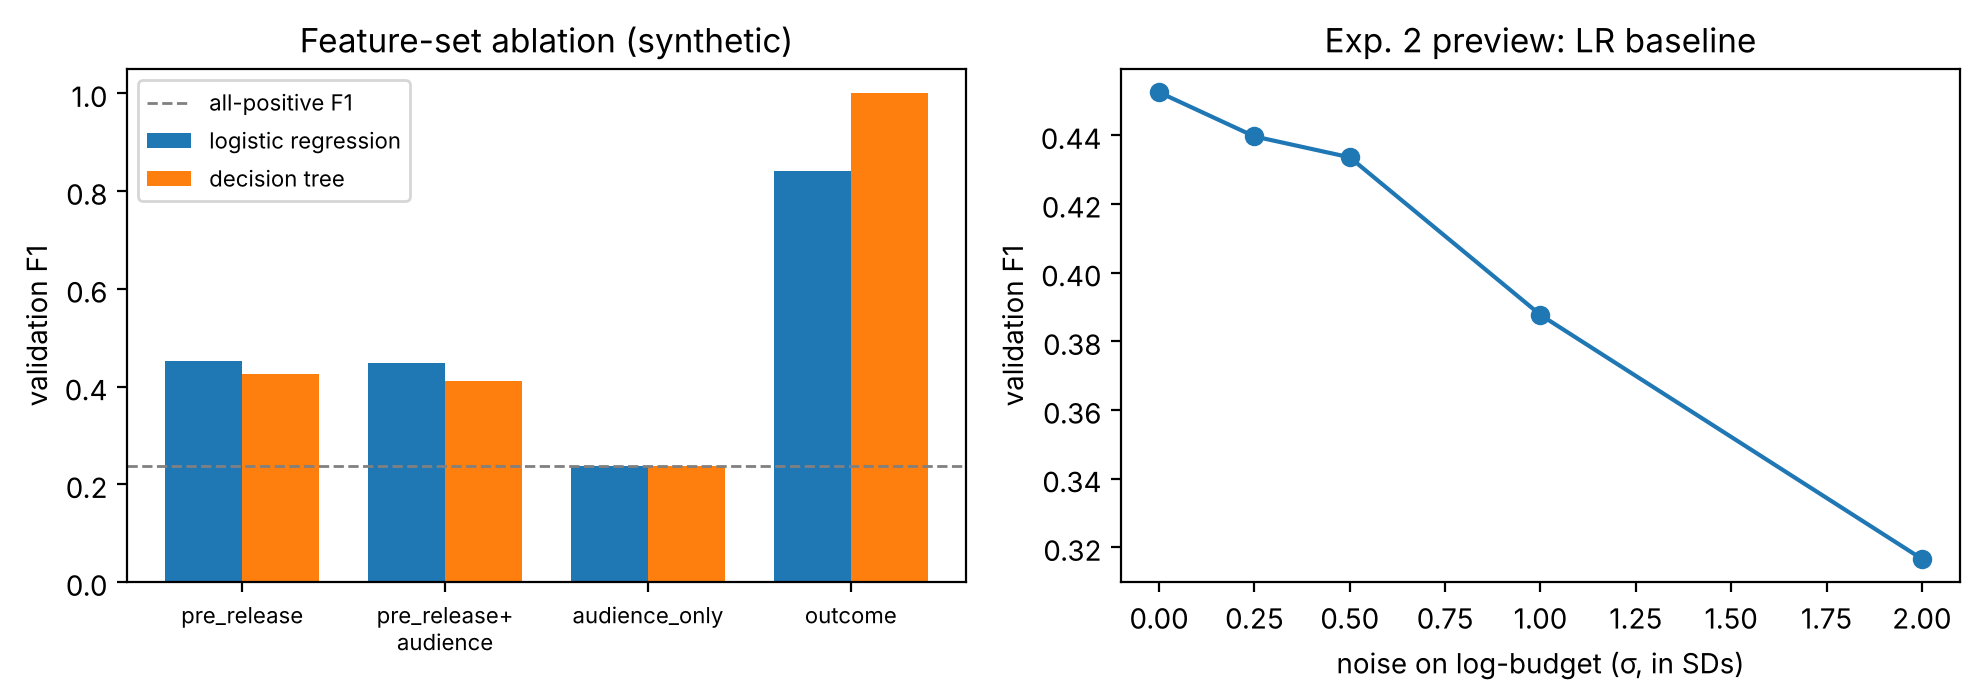

In [17]:
# AI-generated (Claude)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
a = ablation.reset_index()
for i, m in enumerate(["logistic_regression", "decision_tree"]):
    d = a[a.model == m]
    ax[0].bar(np.arange(len(d)) + i * 0.38, d.F1, width=0.38, label=m.replace("_", " "))
ax[0].set_xticks(np.arange(len(FEATURE_SETS)) + 0.19, [k.replace("+", "+\n") for k in FEATURE_SETS], fontsize=8)
ax[0].axhline(baseline.loc["dummy_all_positive", "F1"], ls="--", c="grey", lw=1, label="all-positive F1")
ax[0].set_ylabel("validation F1"); ax[0].set_title("Feature-set ablation (synthetic)"); ax[0].legend(fontsize=8)
n = exp2.iloc[:5]
ax[1].plot([0, 0.25, 0.5, 1, 2], n.F1, marker="o")
ax[1].set_xlabel("noise on log-budget (σ, in SDs)"); ax[1].set_ylabel("validation F1"); ax[1].set_title("Exp. 2 preview: LR baseline")
plt.tight_layout(); plt.savefig(OUT / "checkpoint_figures.png", dpi=150); plt.show()

## 7. Sealed test evaluation (final report only)

In [18]:
# AI-generated (Claude)
if RUN_TEST:
    final = {m: fit_eval(m, FEATURE_SETS["pre_release"], pd.concat([syn_tr, syn_va]), syn_te)[0]
             for m in ["logistic_regression", "decision_tree", "random_forest"]}
    display(pd.DataFrame(final).T)
else:
    print("Test split untouched. Set RUN_TEST = True once, for the final report.")

Test split untouched. Set RUN_TEST = True once, for the final report.
